# Colorectal cancer preprocess

Build raw-count matrices for the 32 µm Visium HD bins and the Xenium section. Neither matrix is a 60% molecule split.

HD and Xenium each contribute their 2,000 most variable genes. The fitted panel is the intersection of those two lists. Variability is the variance of $\log(1+\mathrm{CP10k})$ expression, the same ranking Scanpy uses for `flavor="seurat"`. Mitochondrial genes are excluded before ranking.

The single-cell reference is not used to choose genes. It supplies a plug-in profile: for each broad cell type, the mean of the per-cell fractions computed on the panel genes alone. `prepare_xenium.py` then rebuilds one Xenium matrix per annotated cell type from the new counts.


In [1]:
from pathlib import Path
import json
import shutil
import subprocess
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

ROOT = Path("/home/byual/MMF_codes")
sys.path.insert(0, str(ROOT))
from MMF.mmf import compute_reference_mean

HD_PATH = Path("/import/home4/byual/BGP_codes/experiments_20261023/data/SPATCH_COAD_32um/aggregated_raw_counts.h5ad")
XE_PATH = Path("/home/byual/Xenium_HD/data/SPATCH/COAD/Xenium/section_unresolved/original/extracted/transcriptome/adata.h5ad")
SC_SOURCE = Path("/home/byual/Xenium_HD/data/SPATCH/COAD/scRNA/section_unresolved/original/adata.h5ad")
OUT = ROOT / "data/colorectal_cancer"
FIG = ROOT / "Colorectal_cancer/preprocess_figures"
FIG.mkdir(parents=True, exist_ok=True)
SC_COPY = OUT / "scRNA.h5ad"

N_HVG = 2000
MIN_CELLS = 20
HD_MIN_COUNTS = 50
HD_MIN_GENES = 100
XE_MIN_COUNTS = 20
XE_MIN_GENES = 20
RARE_TYPES = ("mregDC", "cDC2", "pDC")


## Copy the single-cell reference and load all three count matrices

HD bins are the published 32 µm aggregates. Xenium cells keep the published `high_quality=1` flag, then a floor of 20 UMIs and 20 genes. The single-cell object is already limited to cells with at least 1,001 UMIs and 500 genes, and its mitochondrial fraction stays below 0.10. HD bins below 50 UMIs or 100 genes are removed; that also removes the bins previously dropped only because their 60% training draw was small.


In [2]:
shutil.copy2(SC_SOURCE, SC_COPY)
print(f"copied scRNA to {SC_COPY} ({SC_COPY.stat().st_size} bytes)")

def as_csr(matrix):
    if sparse.issparse(matrix):
        return matrix.tocsr()
    return sparse.csr_matrix(matrix)

def mitochondrial(genes):
    return np.array([str(gene).startswith("MT-") or str(gene).startswith("mt-") for gene in genes])

hd = ad.read_h5ad(HD_PATH)
xe = ad.read_h5ad(XE_PATH)
sc = ad.read_h5ad(SC_COPY)
for name, data in (("HD", hd), ("Xenium", xe), ("scRNA", sc)):
    values = data.X.data
    print(name, data.shape, "integer", np.all(values == np.floor(values)), "min", values.min())


copied scRNA to /home/byual/MMF_codes/data/colorectal_cancer/scRNA.h5ad (159652464 bytes)


HD (37775, 4396) integer True min 1


Xenium (405927, 5001) integer True min 1.0
scRNA (8288, 23246) integer True min 1


In [3]:
def qc_table(counts, genes):
    total = np.asarray(counts.sum(1)).ravel()
    detected = np.diff(counts.indptr)
    mt = mitochondrial(genes)
    mt_counts = np.asarray(counts[:, mt].sum(1)).ravel() if mt.any() else np.zeros(counts.shape[0])
    return dict(total=total, detected=detected, mt_fraction=mt_counts / np.maximum(total, 1))

hd_counts = as_csr(hd.X)
xe_counts = as_csr(xe.X)
sc_counts = as_csr(sc.X)
hd_qc = qc_table(hd_counts, hd.var_names)
xe_qc = qc_table(xe_counts, xe.var_names)
sc_qc = qc_table(sc_counts, sc.var_names)
xe_published = xe.obs["high_quality"].astype(str).to_numpy() == "1"
hd_keep = (hd_qc["total"] >= HD_MIN_COUNTS) & (hd_qc["detected"] >= HD_MIN_GENES)
xe_keep = xe_published & (xe_qc["total"] >= XE_MIN_COUNTS) & (xe_qc["detected"] >= XE_MIN_GENES)
sc_keep = np.ones(sc.n_obs, dtype=bool)
print("HD", int(hd_keep.sum()), "of", hd.n_obs)
print("Xenium", int(xe_keep.sum()), "of", int(xe_published.sum()), "published high-quality cells")
print("scRNA", int(sc_keep.sum()), "mitochondrial median", float(np.median(sc_qc["mt_fraction"])))


HD 36503 of 37775
Xenium 365416 of 365416 published high-quality cells
scRNA 8288 mitochondrial median 0.000706838686146886


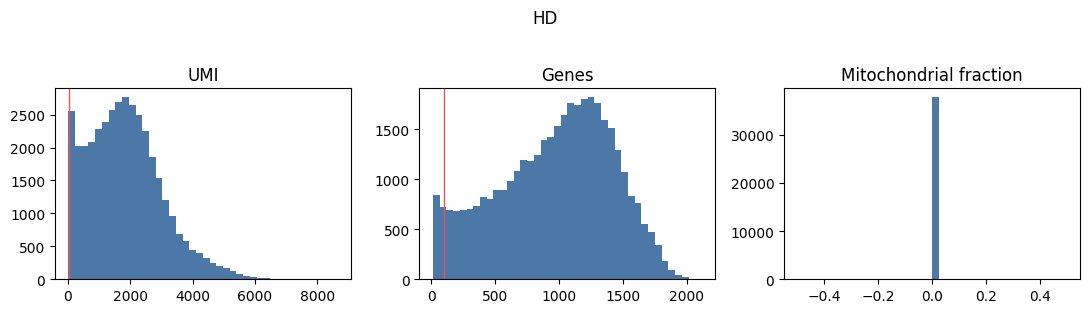

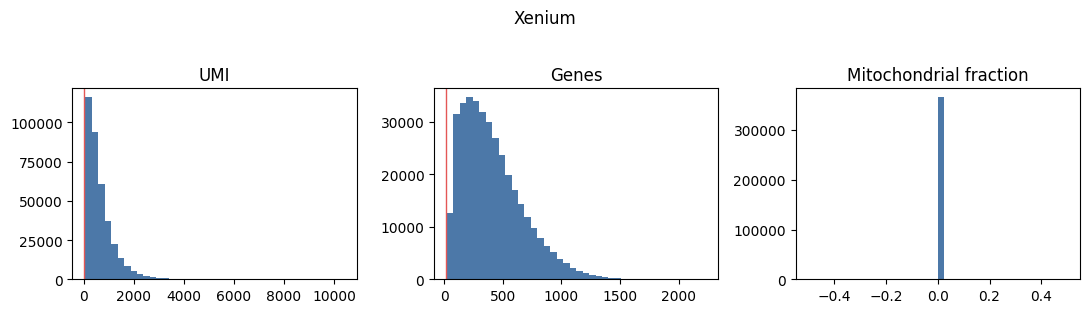

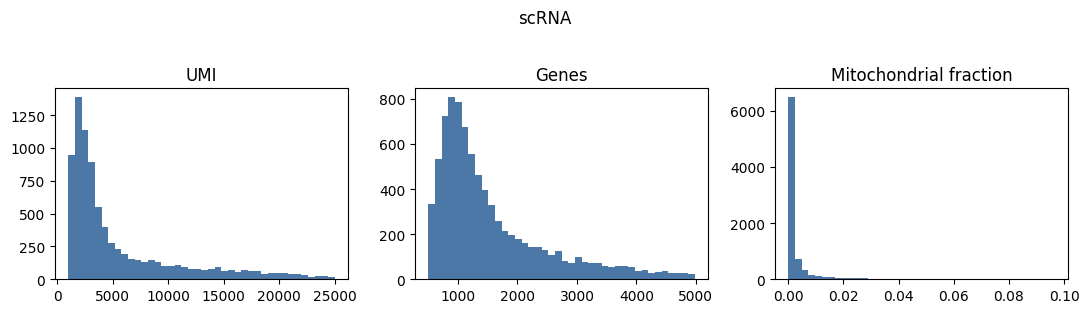

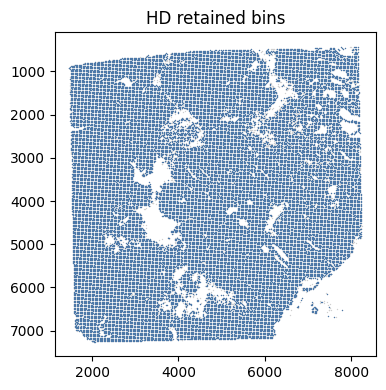

In [4]:
%matplotlib inline

def histograms(name, qc, keep, count_line=None, gene_line=None):
    figure, axes = plt.subplots(1, 3, figsize=(11, 3))
    axes[0].hist(qc["total"][keep], bins=40, color="#4C78A8")
    if count_line:
        axes[0].axvline(count_line, color="#E45756", lw=1)
    axes[0].set_title("UMI")
    axes[1].hist(qc["detected"][keep], bins=40, color="#4C78A8")
    if gene_line:
        axes[1].axvline(gene_line, color="#E45756", lw=1)
    axes[1].set_title("Genes")
    axes[2].hist(qc["mt_fraction"][keep], bins=40, color="#4C78A8")
    axes[2].set_title("Mitochondrial fraction")
    figure.suptitle(name, y=1.03)
    figure.tight_layout()
    figure.savefig(FIG / f"{name}_qc.png", dpi=160, bbox_inches="tight")
    plt.show()

histograms("HD", hd_qc, np.ones(hd.n_obs, dtype=bool), HD_MIN_COUNTS, HD_MIN_GENES)
histograms("Xenium", xe_qc, xe_published, XE_MIN_COUNTS, XE_MIN_GENES)
histograms("scRNA", sc_qc, sc_keep)
coords = np.asarray(hd.obsm["spatial"])
figure, axis = plt.subplots(figsize=(4.2, 4))
axis.scatter(coords[:, 0], coords[:, 1], s=1, c="#D0D0D0", linewidths=0)
axis.scatter(coords[hd_keep, 0], coords[hd_keep, 1], s=1, c="#4C78A8", linewidths=0)
axis.set_aspect("equal")
axis.invert_yaxis()
axis.set_title("HD retained bins")
figure.tight_layout()
figure.savefig(FIG / "HD_spots.png", dpi=160, bbox_inches="tight")
plt.show()


## Highly variable genes and the shared panel


In [5]:
def highly_variable(counts, genes, min_cells):
    genes = np.asarray(genes, dtype=str)
    detected = np.asarray((counts > 0).sum(0)).ravel()
    eligible = (detected >= min_cells) & ~mitochondrial(genes)
    library = np.asarray(counts.sum(1)).ravel().astype(np.float64)
    present = library > 0
    scaled = sparse.diags((1e4 / library[present]).astype(np.float64)) @ counts[present].astype(np.float64)
    scaled.data = np.log1p(scaled.data)
    n = scaled.shape[0]
    mean = np.asarray(scaled.sum(0)).ravel() / n
    scaled.data **= 2
    variance = np.asarray(scaled.sum(0)).ravel() / n - mean ** 2
    variance = np.where(eligible, variance, -np.inf)
    order = np.argsort(-variance, kind="stable")[:N_HVG]
    if not np.isfinite(variance[order]).all():
        raise RuntimeError("Fewer than 2000 eligible genes")
    return pd.DataFrame({"gene": genes[order], "variance": variance[order], "rank": np.arange(1, N_HVG + 1)})

hvg = {
    "HD": highly_variable(hd_counts[hd_keep], hd.var_names, MIN_CELLS),
    "Xenium": highly_variable(xe_counts[xe_keep], xe.var_names, MIN_CELLS),
}
for name, table in hvg.items():
    print(name, "top", table.gene.iloc[0], "rank 2000", table.gene.iloc[-1])
selected = {name: set(table.gene) for name, table in hvg.items()}
panel = np.array(sorted(selected["HD"] & selected["Xenium"]), dtype=str)
print("HD and Xenium intersection", len(panel))
if len(panel) == 0:
    raise RuntimeError("The HD and Xenium HVG lists do not intersect")


HD top COL4A1 rank 2000 EZH1
Xenium top COL4A1 rank 2000 SOAT1
HD and Xenium intersection 1571


## Reference mean and raw spatial counts

`eta0` is a plug-in reference. Within each broad cell type it is the mean of the per-cell UMI fractions on the panel genes only, so each type's profile sums to one. Rare dendritic labels `mregDC`, `cDC2`, and `pDC` are merged into `Other`. `Y` stores observed UMIs. `library_size` is the row sum of `Y`.


In [6]:
def broad_labels(annotation):
    labels = np.asarray(annotation, dtype=str)
    return np.where(np.isin(labels, RARE_TYPES), "Other", labels)

sc_index = {gene: i for i, gene in enumerate(map(str, sc.var_names))}
missing = [gene for gene in panel if gene not in sc_index]
if missing:
    raise RuntimeError(f"Panel genes absent from the single-cell reference: {missing[:10]}")
panel_counts = sc_counts[:, [sc_index[gene] for gene in panel]].toarray()
labels = broad_labels(sc.obs["major_annotation"])
types = np.array(sorted(set(labels.tolist())), dtype=str)
eta0, eta_types = compute_reference_mean(panel_counts, labels, cell_types=types.tolist())
eta0 = eta0.astype(np.float32)
assert list(eta_types) == types.tolist()
assert np.isfinite(eta0).all() and (eta0 >= 0).all()
assert np.allclose(eta0.sum(1), 1, atol=1e-5)
print(pd.Series(labels).value_counts().reindex(types).to_string())
print("panel", len(panel), "reference cells with panel UMIs", int((panel_counts.sum(1) > 0).sum()))


B                69
CD4T           1520
CD8T           1297
Endothelial     230
Epithelial      979
Fibroblast      471
Macrophage      862
Mast             54
Monocyte        144
Neutrophil     1262
Other            78
Plasma         1017
SMC             160
Tprolif         145
panel 1571 reference cells with panel UMIs 8288


In [7]:
def initial_pi(counts, profiles):
    library = counts.sum(1, keepdims=True).astype(np.float64)
    projected = (counts.astype(np.float64) @ profiles.T) / library
    weights = projected @ np.linalg.pinv(profiles @ profiles.T, hermitian=True)
    weights = np.maximum(weights, 1e-3)
    weights /= weights.sum(1, keepdims=True)
    return weights.astype(np.float32)

def fit_coordinates(raw):
    origin = raw.min(0)
    scale = float(np.ptp(raw, axis=0).max())
    return ((raw - origin) / scale).astype(np.float32), origin, scale

def save_spatial(name, counts, genes, keep, coordinates, obs_names):
    column = [list(map(str, genes)).index(gene) for gene in panel]
    observed = counts[keep][:, column]
    if sparse.issparse(observed):
        observed = observed.toarray()
    positive = observed.sum(1) > 0
    observed = np.asarray(observed[positive], dtype=np.float32)
    raw_coords = np.asarray(coordinates, dtype=np.float64)[keep][positive]
    coords, origin, scale = fit_coordinates(raw_coords)
    payload = dict(
        Y=observed, eta0=eta0, pi=initial_pi(observed, eta0), coords=coords,
        library_size=observed.sum(1).astype(np.float64), genes=panel, cell_types=types,
        original_indices=np.flatnonzero(keep)[positive].astype(np.int64),
        original_coords=raw_coords, spot_names=np.asarray(obs_names, dtype=str)[keep][positive],
    )
    assert np.array_equal(payload["library_size"], payload["Y"].sum(1))
    assert np.all(payload["library_size"] > 0)
    assert np.max(np.abs(payload["Y"] - np.round(payload["Y"]))) == 0
    destination = OUT / f"{name}.npz"
    temporary = OUT / f".{name}.partial.npz"
    np.savez_compressed(temporary, **payload)
    temporary.replace(destination)
    print(name, observed.shape, "origin", origin.tolist(), "scale", scale)
    return payload

hd_payload = save_spatial("HD_data", hd_counts, hd.var_names, hd_keep, hd.obsm["spatial"], hd.obs_names)
xe_payload = save_spatial("Xenium_data", xe_counts, xe.var_names, xe_keep, xe.obsm["spatial"], xe.obs_names)


HD_data (36503, 1571) origin [1478.432930502254, 441.89848547270526] scale 6808.874567814299


Xenium_data (365416, 1571) origin [570.5715942382812, 159.72274780273438] scale 10290.430358886719


## Keep the HD marker and annotation files on the same bins

Secretory marker counts stay on their original full-transcriptome values. Rows are restricted to the bins retained above, in the same order as `HD_data.npz`.


In [8]:
def align_auxiliary(filename, payload):
    stored = np.load(OUT / filename, allow_pickle=False)
    order = {name: i for i, name in enumerate(stored["spot_names"].astype(str))}
    index = np.array([order[name] for name in payload["spot_names"].astype(str)])
    aligned = {key: stored[key][index] if stored[key].shape[0] == stored["spot_names"].shape[0] else stored[key]
               for key in stored.files}
    aligned["spot_names"] = payload["spot_names"]
    aligned["coords"] = payload["coords"]
    aligned["original_coords"] = payload["original_coords"]
    temporary = OUT / f".{filename}.partial.npz"
    np.savez_compressed(temporary, **aligned)
    temporary.replace(OUT / filename)
    print(filename, aligned["spot_names"].shape[0])

align_auxiliary("hd32_markers.npz", hd_payload)
align_auxiliary("hd32_original_annotation_fractions.npz", hd_payload)


hd32_markers.npz 36503


hd32_original_annotation_fractions.npz 36503


In [9]:
scores = []
for name, table in hvg.items():
    part = table.copy()
    part.insert(0, "assay", name)
    part["in_panel"] = part["gene"].isin(set(panel))
    scores.append(part)
pd.concat(scores, ignore_index=True).to_csv(OUT / "hvg_selection.csv", index=False)
manifest = dict(
    count_policy="Observed UMI on the shared panel. No molecule split and no train/test partition.",
    hvg="Variance of log1p(CP10k) on HD and Xenium. Panel is the intersection of the two top-2000 lists.",
    hvg_per_assay=N_HVG,
    panel_genes=int(len(panel)),
    qc=dict(hd_min_counts=HD_MIN_COUNTS, hd_min_genes=HD_MIN_GENES,
            xenium_published_high_quality=True, xenium_min_counts=XE_MIN_COUNTS,
            xenium_min_genes=XE_MIN_GENES, min_cells_for_hvg=MIN_CELLS,
            scrna_source_already_filtered=True),
    spots=dict(HD=int(hd_payload["Y"].shape[0]), Xenium=int(xe_payload["Y"].shape[0]),
               scRNA=int(sc_keep.sum())),
    cell_types=types.tolist(),
    rare_types_merged_to_Other=list(RARE_TYPES),
    eta0="Plug-in mean within broad type of per-cell fractions on the panel genes only.",
    scrna=str(SC_COPY),
    scrna_source=str(SC_SOURCE),
)
(OUT / "preprocess_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print(json.dumps(manifest, indent=2))


{
  "count_policy": "Observed UMI on the shared panel. No molecule split and no train/test partition.",
  "hvg": "Variance of log1p(CP10k) on HD and Xenium. Panel is the intersection of the two top-2000 lists.",
  "hvg_per_assay": 2000,
  "panel_genes": 1571,
  "qc": {
    "hd_min_counts": 50,
    "hd_min_genes": 100,
    "xenium_published_high_quality": true,
    "xenium_min_counts": 20,
    "xenium_min_genes": 20,
    "min_cells_for_hvg": 20,
    "scrna_source_already_filtered": true
  },
  "spots": {
    "HD": 36503,
    "Xenium": 365416,
    "scRNA": 8288
  },
  "cell_types": [
    "B",
    "CD4T",
    "CD8T",
    "Endothelial",
    "Epithelial",
    "Fibroblast",
    "Macrophage",
    "Mast",
    "Monocyte",
    "Neutrophil",
    "Other",
    "Plasma",
    "SMC",
    "Tprolif"
  ],
  "rare_types_merged_to_Other": [
    "mregDC",
    "cDC2",
    "pDC"
  ],
  "eta0": "Plug-in mean within broad type of per-cell fractions on the panel genes only.",
  "scrna": "/home/byual/MMF_codes/da

## Per-type Xenium matrices

`prepare_xenium.py` reads the new `Xenium_data.npz` and writes one raw-count matrix for each annotated cell type.


In [10]:
subprocess.run([sys.executable, str(ROOT / "Colorectal_cancer/prepare_xenium.py")], check=True)


[
  {
    "cell_type": "B",
    "N": 2365,
    "G": 1410
  },
  {
    "cell_type": "CD4T",
    "N": 16786,
    "G": 1568
  },
  {
    "cell_type": "CD8T",
    "N": 11673,
    "G": 1565
  },
  {
    "cell_type": "Endothelial",
    "N": 13924,
    "G": 1553
  },
  {
    "cell_type": "Epithelial",
    "N": 181052,
    "G": 1571
  },
  {
    "cell_type": "Fibroblast",
    "N": 49497,
    "G": 1568
  },
  {
    "cell_type": "Macrophage",
    "N": 21686,
    "G": 1568
  },
  {
    "cell_type": "Mast",
    "N": 922,
    "G": 1389
  },
  {
    "cell_type": "Monocyte",
    "N": 2047,
    "G": 1488
  },
  {
    "cell_type": "Neutrophil",
    "N": 10784,
    "G": 1568
  },
  {
    "cell_type": "Other",
    "N": 2525,
    "G": 1491
  },
  {
    "cell_type": "Plasma",
    "N": 35479,
    "G": 1566
  },
  {
    "cell_type": "SMC",
    "N": 12688,
    "G": 1551
  },
  {
    "cell_type": "Tprolif",
    "N": 3988,
    "G": 1520
  }
]


CompletedProcess(args=['/home/byual/anaconda3/envs/pytorch/bin/python', '/home/byual/MMF_codes/Colorectal_cancer/prepare_xenium.py'], returncode=0)